In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df=pd.read_csv(r'/content/Adult Census Income.csv')

In [3]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [5]:
df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education.num,0
marital.status,0
occupation,0
relationship,0
race,0
sex,0


In [6]:
from sklearn.impute import SimpleImputer
imputer=SimpleImputer(missing_values='?',strategy='most_frequent')
df['occupation']=imputer.fit_transform(df['occupation'].values.reshape(-1,1))[:,0]
df['occupation']

,occupation
0,Prof-specialty
1,Exec-managerial
2,Prof-specialty
3,Machine-op-inspct
4,Prof-specialty
...,...
32556,Protective-serv
32557,Tech-support
32558,Machine-op-inspct
32559,Adm-clerical


In [7]:
from sklearn.impute import SimpleImputer
imputer=SimpleImputer(missing_values='?',strategy='most_frequent')
df['workclass']=imputer.fit_transform(df['workclass'].values.reshape(-1,1))[:,0]
df['workclass']

,workclass
0,Private
1,Private
2,Private
3,Private
4,Private
...,...
32556,Private
32557,Private
32558,Private
32559,Private


In [8]:
df.isnull().sum().sum()

np.int64(0)

In [9]:
df.duplicated().sum()

np.int64(24)

In [10]:
df.drop_duplicates(inplace=True)

In [11]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,Private,77053,HS-grad,9,Widowed,Prof-specialty,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,Private,186061,Some-college,10,Widowed,Prof-specialty,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [12]:
from sklearn.impute import SimpleImputer
imputer=SimpleImputer(missing_values='?',strategy='most_frequent')
df['native.country']=imputer.fit_transform(df['native.country'].values.reshape(-1,1))[:,0]
df['native.country']

,native.country
0,United-States
1,United-States
2,United-States
3,United-States
4,United-States
...,...
32556,United-States
32557,United-States
32558,United-States
32559,United-States


In [13]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education.num',
       'marital.status', 'occupation', 'relationship', 'race', 'sex',
       'capital.gain', 'capital.loss', 'hours.per.week', 'native.country',
       'income'],
      dtype='object')

<Axes: xlabel='income', ylabel='count'>

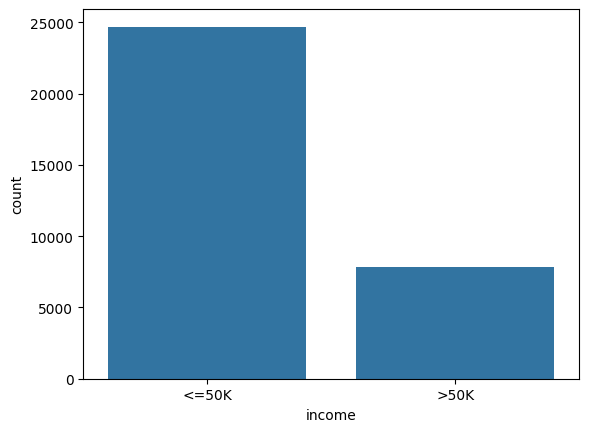

In [14]:
sns.countplot(data=df, x='income')


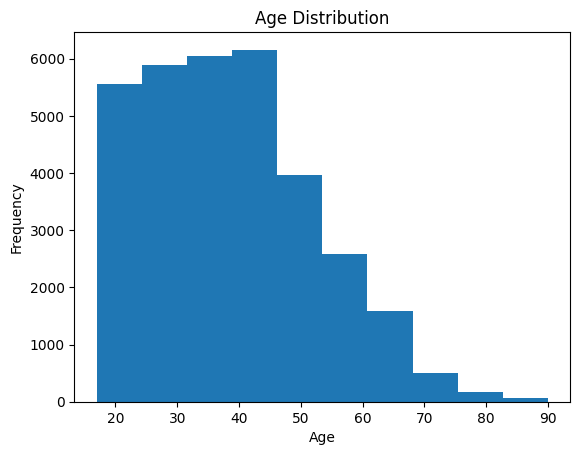

In [15]:
plt.hist(df['age'])
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution')
plt.show()

<Axes: xlabel='income', ylabel='hours.per.week'>

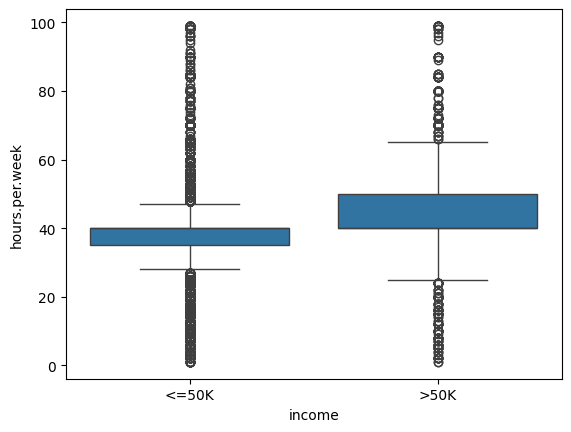

In [16]:
sns.boxplot(data=df, x='income', y='hours.per.week')


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15],
 [Text(0, 0, 'HS-grad'),
  Text(1, 0, 'Some-college'),
  Text(2, 0, '7th-8th'),
  Text(3, 0, '10th'),
  Text(4, 0, 'Doctorate'),
  Text(5, 0, 'Prof-school'),
  Text(6, 0, 'Bachelors'),
  Text(7, 0, 'Masters'),
  Text(8, 0, '11th'),
  Text(9, 0, 'Assoc-acdm'),
  Text(10, 0, 'Assoc-voc'),
  Text(11, 0, '1st-4th'),
  Text(12, 0, '5th-6th'),
  Text(13, 0, '12th'),
  Text(14, 0, '9th'),
  Text(15, 0, 'Preschool')])

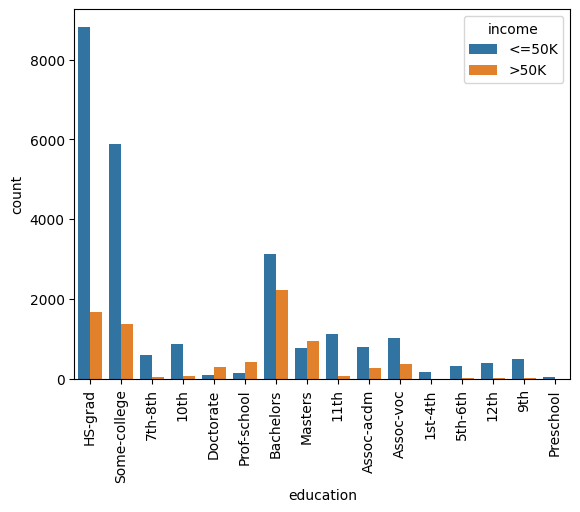

In [17]:
sns.countplot(data=df, x='education', hue='income')
plt.xticks(rotation=90)


<Axes: xlabel='age', ylabel='hours.per.week'>

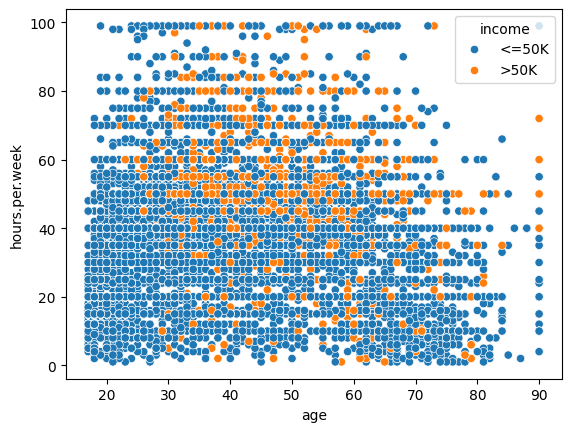

In [18]:
sns.scatterplot(data=df, x='age', y='hours.per.week', hue='income')

In [19]:
for col in df.select_dtypes(include=['object']):
    print(col)
    print(df[col].value_counts())
    print()

workclass
workclass
Private             24509
Self-emp-not-inc     2540
Local-gov            2093
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64

education
education
HS-grad         10494
Some-college     7282
Bachelors        5353
Masters          1722
Assoc-voc        1382
11th             1175
Assoc-acdm       1067
10th              933
7th-8th           645
Prof-school       576
9th               514
12th              433
Doctorate         413
5th-6th           332
1st-4th           166
Preschool          50
Name: count, dtype: int64

marital.status
marital.status
Married-civ-spouse       14970
Never-married            10667
Divorced                  4441
Separated                 1025
Widowed                    993
Married-spouse-absent      418
Married-AF-spouse           23
Name: count, dtype: int64

occupation
occupation
Prof-specialty       5979
Craft-repair         409

In [20]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
for col in df.select_dtypes(include=['object']):
    df[col]=le.fit_transform(df[col])

In [21]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,3,77053,11,9,6,9,1,4,0,0,4356,40,38,0
1,82,3,132870,11,9,6,3,1,4,0,0,4356,18,38,0
2,66,3,186061,15,10,6,9,4,2,0,0,4356,40,38,0
3,54,3,140359,5,4,0,6,4,4,0,0,3900,40,38,0
4,41,3,264663,15,10,5,9,3,4,0,0,3900,40,38,0


In [22]:
def remove_outliers_iqr(df):
    before = df.shape[0]
    df_clean = df.copy()

    num_cols = df_clean.select_dtypes(include='number').columns.drop(
        'income', errors='ignore'
    )

    for col in num_cols:
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        df_clean = df_clean[
            df_clean[col].between(lower, upper)
        ]

    after = df_clean.shape[0]

    print("Rows before:", before)
    print("Rows after:", after)
    print("Rows removed:", before - after)

    return df_clean

In [23]:
print(df.shape)
df=remove_outliers_iqr(df)
print(df.shape)

(32537, 15)
Rows before: 32537
Rows after: 10775
Rows removed: 21762
(10775, 15)


In [24]:
X=df.drop('income',axis=1)
y=df['income']


In [25]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [26]:
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [27]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
4232,38,3,215646,11,9,0,5,1,4,1,0,0,40,38,0
4235,37,3,284582,12,14,2,3,5,4,0,0,0,40,38,0
4245,32,3,186824,11,9,4,6,4,4,1,0,0,40,38,0
4251,59,3,109015,11,9,0,12,4,4,0,0,0,40,38,0
4253,19,3,168294,11,9,4,2,3,4,1,0,0,40,38,0


In [28]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

In [29]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

In [30]:
y_pred_lr,y_test

(array([1, 0, 1, ..., 1, 0, 1]),
 31452    1
 5204     0
 24333    1
 22351    1
 4322     0
         ..
 13707    0
 9289     0
 14961    0
 11151    0
 29363    0
 Name: income, Length: 2155, dtype: int64)

In [31]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))
print("Classification Report:\n", classification_report(y_test, y_pred_lr))

Accuracy: 0.7299303944315545
Confusion Matrix:
 [[1221  458]
 [ 124  352]]
Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.73      0.81      1679
           1       0.43      0.74      0.55       476

    accuracy                           0.73      2155
   macro avg       0.67      0.73      0.68      2155
weighted avg       0.80      0.73      0.75      2155



In [32]:
from sklearn.linear_model import LinearRegression
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)



In [33]:
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))
print("Classification Report:\n", classification_report(y_test, y_pred_lr))

Accuracy: 0.7299303944315545
Confusion Matrix:
 [[1221  458]
 [ 124  352]]
Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.73      0.81      1679
           1       0.43      0.74      0.55       476

    accuracy                           0.73      2155
   macro avg       0.67      0.73      0.68      2155
weighted avg       0.80      0.73      0.75      2155



In [34]:
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)

In [35]:
print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_nb))
print("Classification Report:\n", classification_report(y_test, y_pred_nb))

Accuracy: 0.7331786542923434
Confusion Matrix:
 [[1206  473]
 [ 102  374]]
Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.72      0.81      1679
           1       0.44      0.79      0.57       476

    accuracy                           0.73      2155
   macro avg       0.68      0.75      0.69      2155
weighted avg       0.82      0.73      0.75      2155



In [36]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred_continuous = lin_reg.predict(X_test)
y_pred_lin = np.where(y_pred_continuous >= 0.5, 1, 0)


acc_lin = accuracy_score(y_test, y_pred_lin)
prec_lin, rec_lin, f1_lin, _ = precision_recall_fscore_support(y_test, y_pred_lin, average='binary')

acc_lr = accuracy_score(y_test, y_pred_lr)
prec_lr, rec_lr, f1_lr, _ = precision_recall_fscore_support(y_test, y_pred_lr, average='binary')

acc_nb = accuracy_score(y_test, y_pred_nb)
prec_nb, rec_nb, f1_nb, _ = precision_recall_fscore_support(y_test, y_pred_nb, average='binary')

comparison_data = {
    'Model': ['Logistic Regression', 'Naive Bayes', 'Linear Regression (Binarized)'],
    'Accuracy': [acc_lr, acc_nb, acc_lin],
    'Precision': [prec_lr, prec_nb, prec_lin],
    'Recall': [rec_lr, rec_nb, rec_lin],
    'F1-Score': [f1_lr, f1_nb, f1_lin]
}

df_compare = pd.DataFrame(comparison_data)
display(df_compare)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.729930,0.434568,0.739496,0.547434
1,Naive Bayes,0.733179,0.441558,0.785714,0.565382
2,Linear Regression (Binarized),0.727610,0.432069,0.741597,0.546017


In [38]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 32.9 MB/s  0:00:03


In [39]:
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

In [40]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[1221  458]
 [ 124  352]]


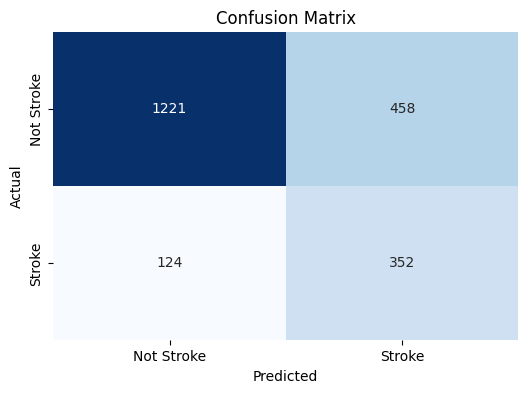


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.91      0.73      0.81      1679
      Stroke       0.43      0.74      0.55       476

    accuracy                           0.73      2155
   macro avg       0.67      0.73      0.68      2155
weighted avg       0.80      0.73      0.75      2155

ROC-AUC: 0.805203677659271


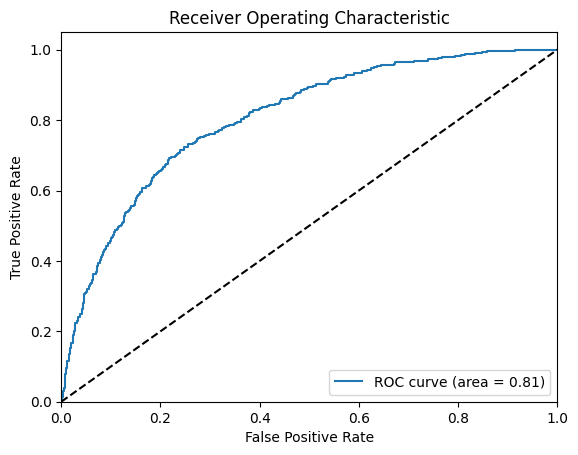

PR AUC: 0.5287222720255909


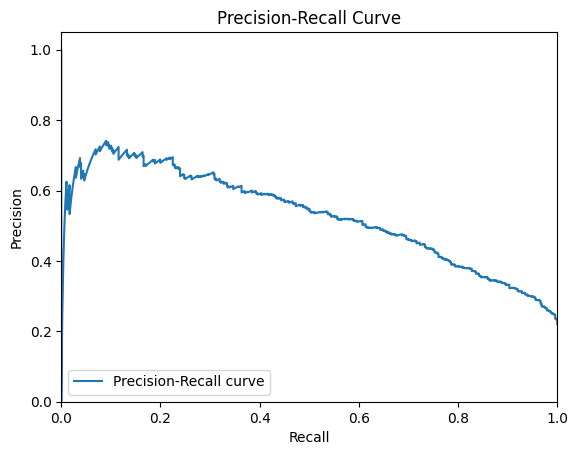

  8%|▊         | 1/13 [00:00<00:09,  1.21it/s]


Confusion Matrix:
 [[1252  427]
 [ 130  346]]


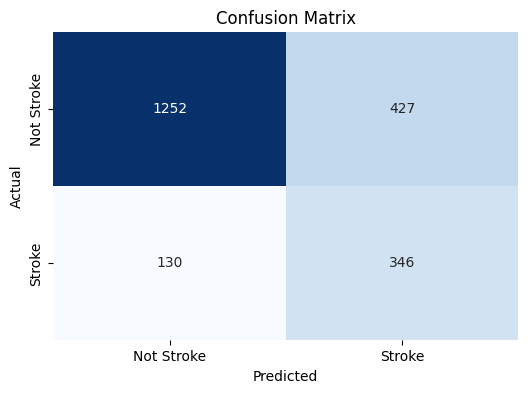


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.91      0.75      0.82      1679
      Stroke       0.45      0.73      0.55       476

    accuracy                           0.74      2155
   macro avg       0.68      0.74      0.69      2155
weighted avg       0.80      0.74      0.76      2155

ROC-AUC: 0.8093765796967983


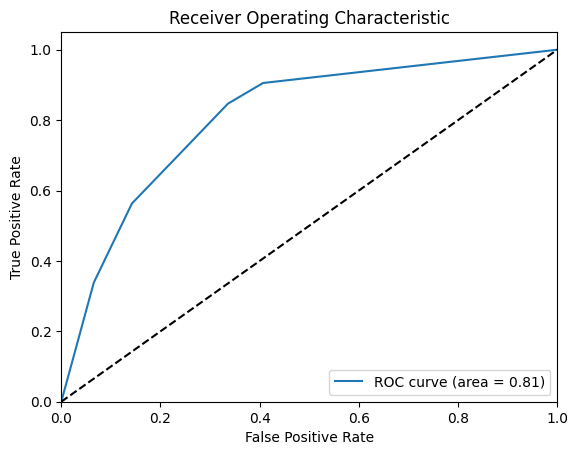

PR AUC: 0.48666082012377915


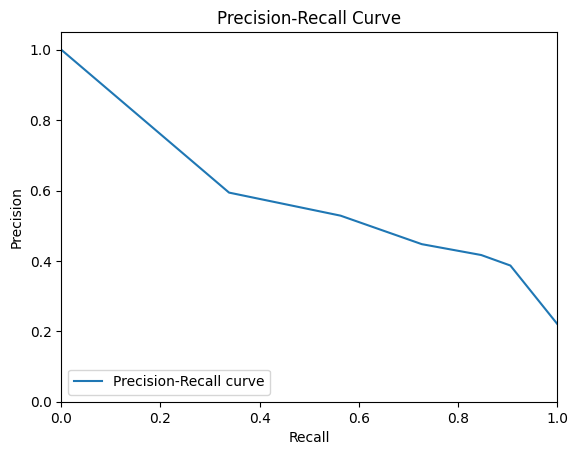

 15%|█▌        | 2/13 [00:03<00:24,  2.18s/it]


Confusion Matrix:
 [[1205  474]
 [  61  415]]


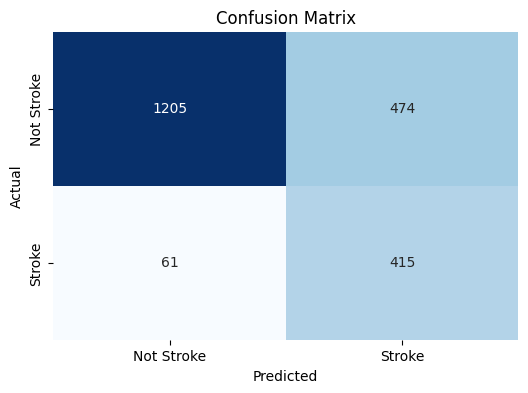


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.72      0.82      1679
      Stroke       0.47      0.87      0.61       476

    accuracy                           0.75      2155
   macro avg       0.71      0.79      0.71      2155
weighted avg       0.84      0.75      0.77      2155

ROC-AUC: 0.8618825731602945


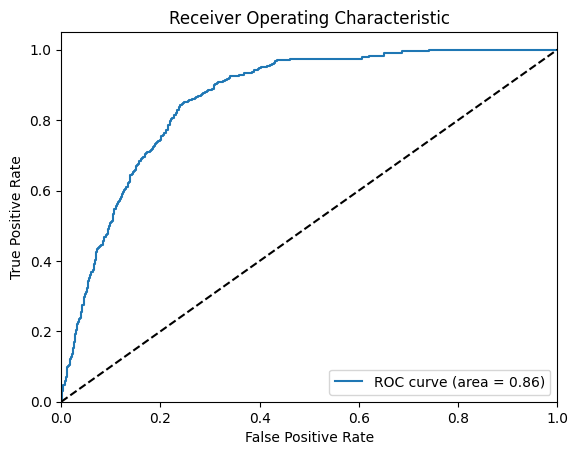

PR AUC: 0.5811613571887143


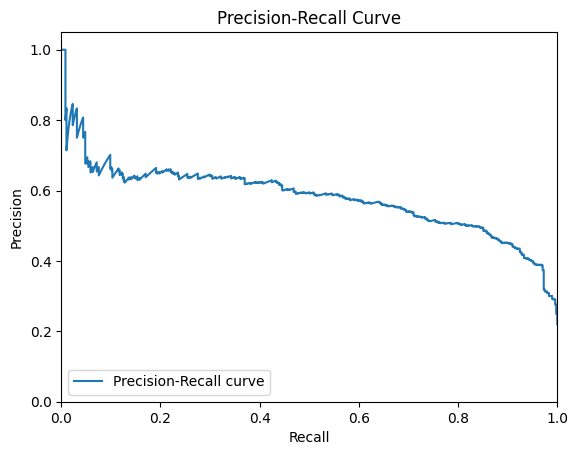

 23%|██▎       | 3/13 [00:52<03:52, 23.25s/it]


Confusion Matrix:
 [[1403  276]
 [ 222  254]]


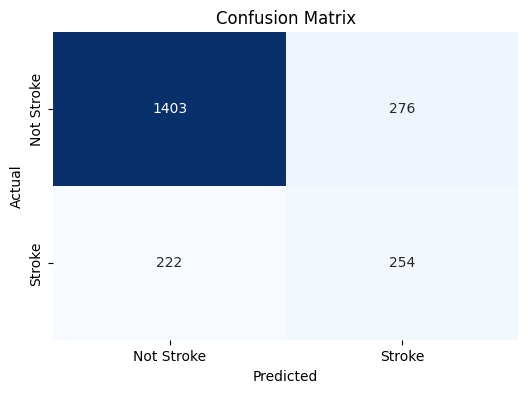


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.86      0.84      0.85      1679
      Stroke       0.48      0.53      0.50       476

    accuracy                           0.77      2155
   macro avg       0.67      0.68      0.68      2155
weighted avg       0.78      0.77      0.77      2155

ROC-AUC: 0.6846149418671578


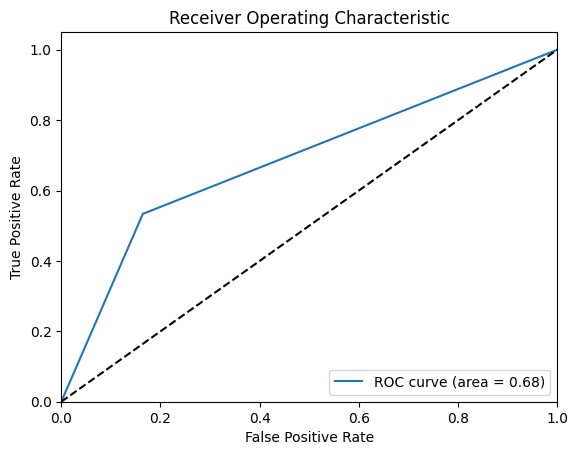

PR AUC: 0.3587479679522293


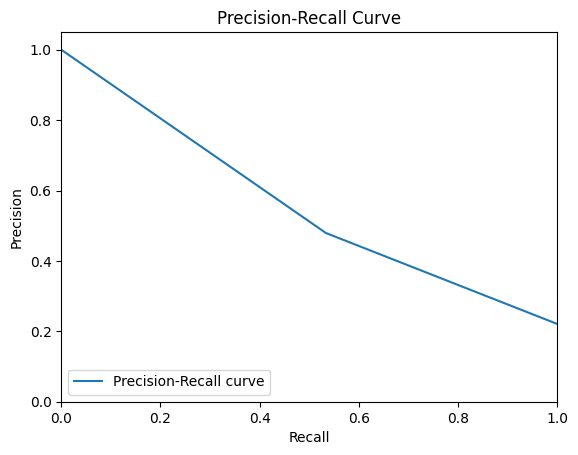

 31%|███       | 4/13 [00:52<02:08, 14.27s/it]


Confusion Matrix:
 [[1206  473]
 [ 102  374]]


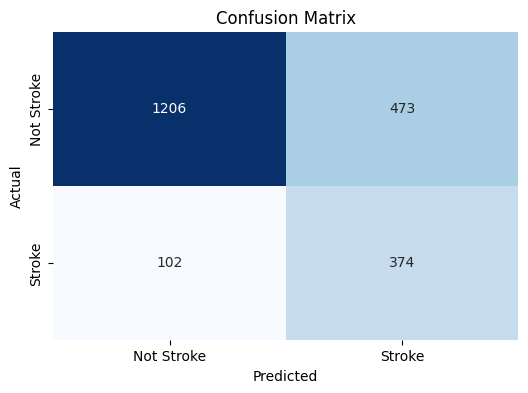


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.92      0.72      0.81      1679
      Stroke       0.44      0.79      0.57       476

    accuracy                           0.73      2155
   macro avg       0.68      0.75      0.69      2155
weighted avg       0.82      0.73      0.75      2155

ROC-AUC: 0.8353674406034004


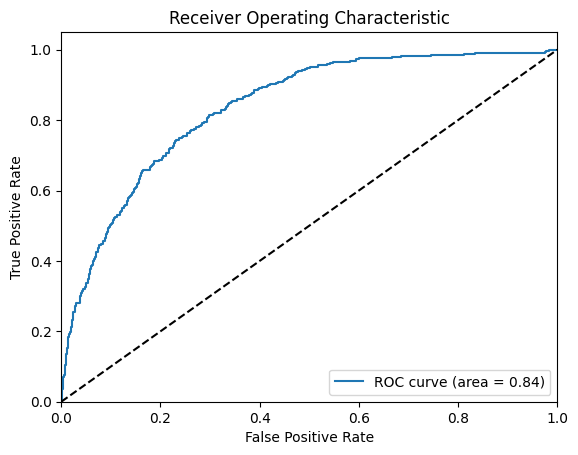

PR AUC: 0.5875666726769526


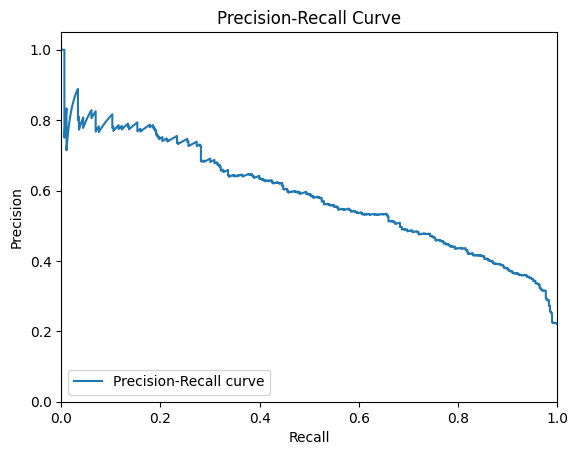

 38%|███▊      | 5/13 [00:53<01:14,  9.28s/it]


Confusion Matrix:
 [[1462  217]
 [ 189  287]]


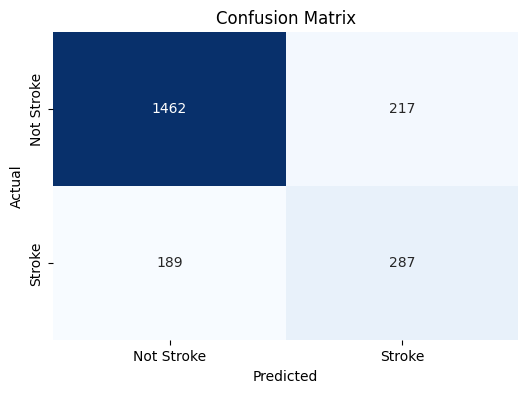


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.87      0.88      1679
      Stroke       0.57      0.60      0.59       476

    accuracy                           0.81      2155
   macro avg       0.73      0.74      0.73      2155
weighted avg       0.82      0.81      0.81      2155

ROC-AUC: 0.8552447184949024


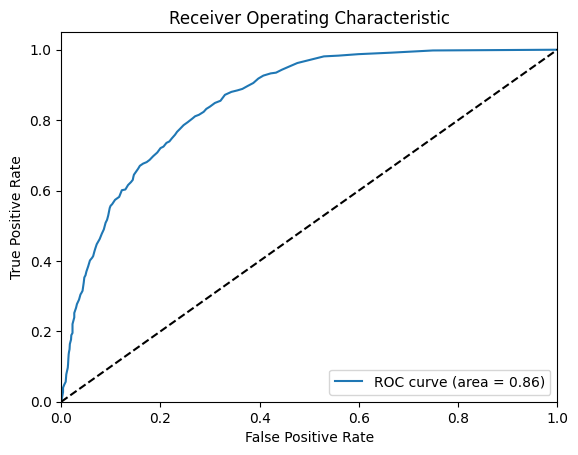

PR AUC: 0.586110790539887


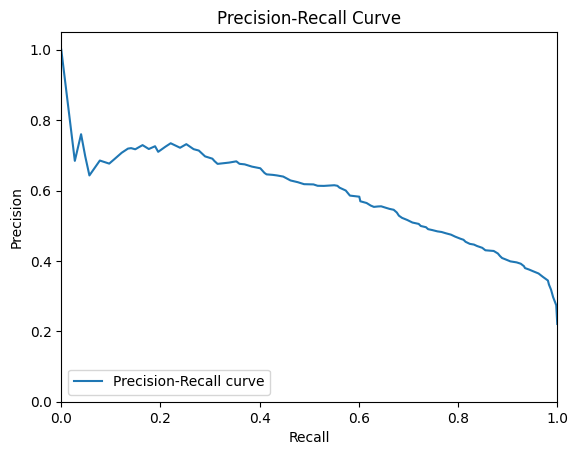

 46%|████▌     | 6/13 [00:55<00:49,  7.06s/it]


Confusion Matrix:
 [[1463  216]
 [ 213  263]]


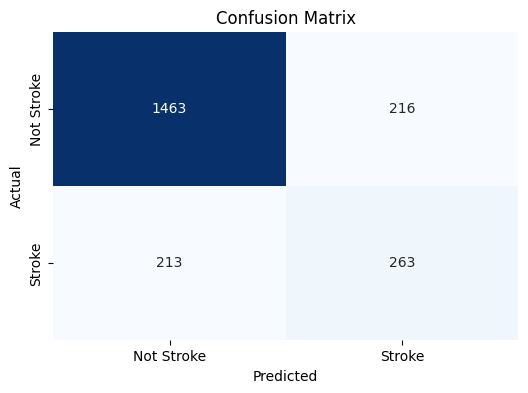


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.87      0.87      1679
      Stroke       0.55      0.55      0.55       476

    accuracy                           0.80      2155
   macro avg       0.71      0.71      0.71      2155
weighted avg       0.80      0.80      0.80      2155

ROC-AUC: 0.8399595097121636


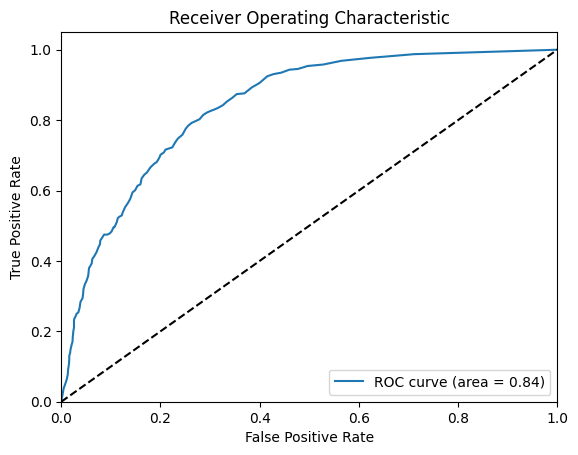

PR AUC: 0.5595501176191604


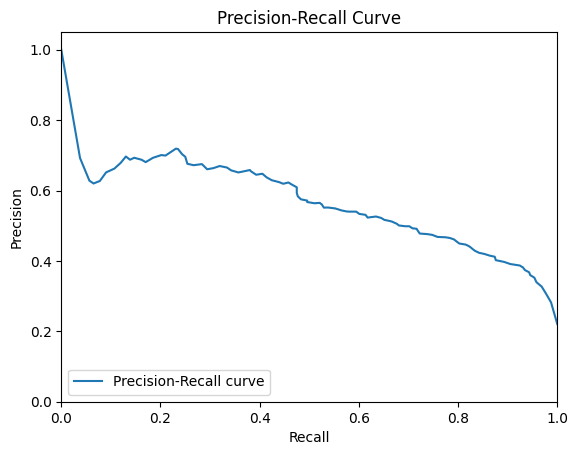

 54%|█████▍    | 7/13 [00:58<00:34,  5.68s/it]


Confusion Matrix:
 [[1288  391]
 [  81  395]]


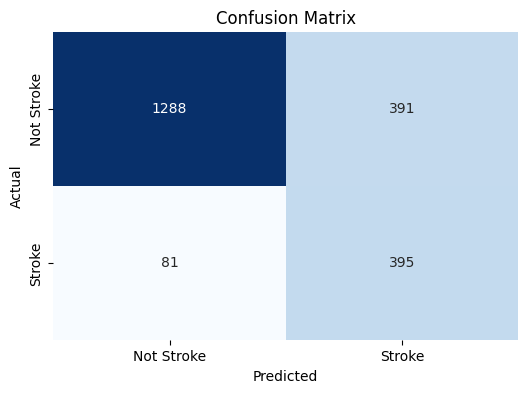


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      0.77      0.85      1679
      Stroke       0.50      0.83      0.63       476

    accuracy                           0.78      2155
   macro avg       0.72      0.80      0.74      2155
weighted avg       0.84      0.78      0.80      2155

ROC-AUC: 0.8705105329803156


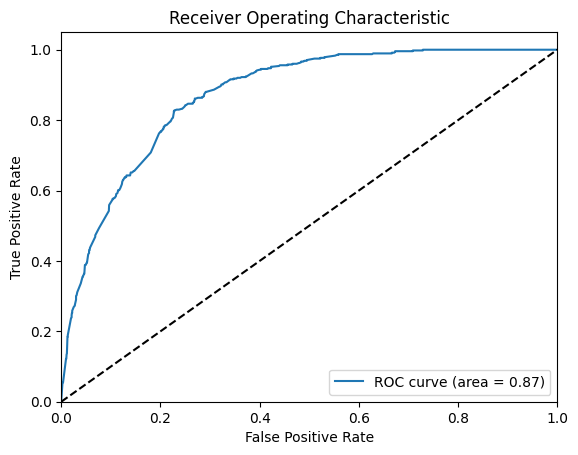

PR AUC: 0.6296134775252032


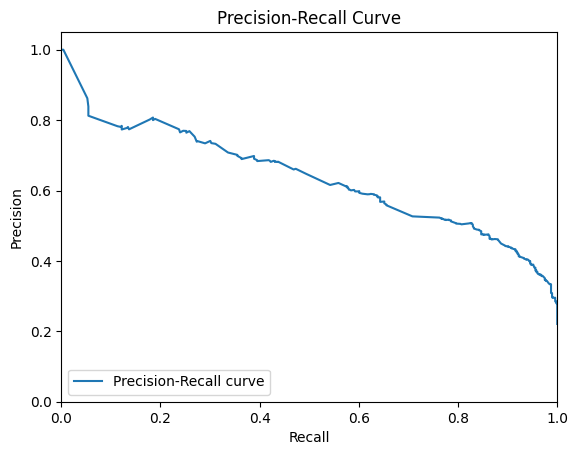

 62%|██████▏   | 8/13 [01:00<00:21,  4.28s/it]


Confusion Matrix:
 [[1350  329]
 [ 100  376]]


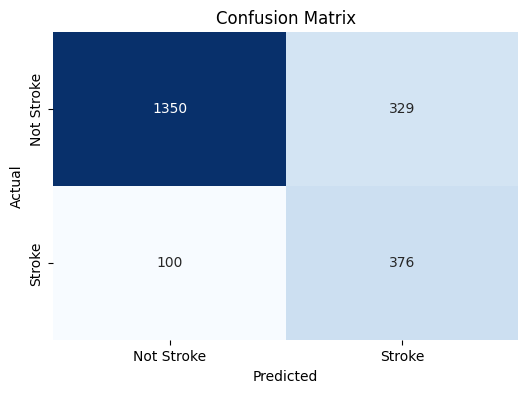


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.93      0.80      0.86      1679
      Stroke       0.53      0.79      0.64       476

    accuracy                           0.80      2155
   macro avg       0.73      0.80      0.75      2155
weighted avg       0.84      0.80      0.81      2155

ROC-AUC: 0.8787280844440218


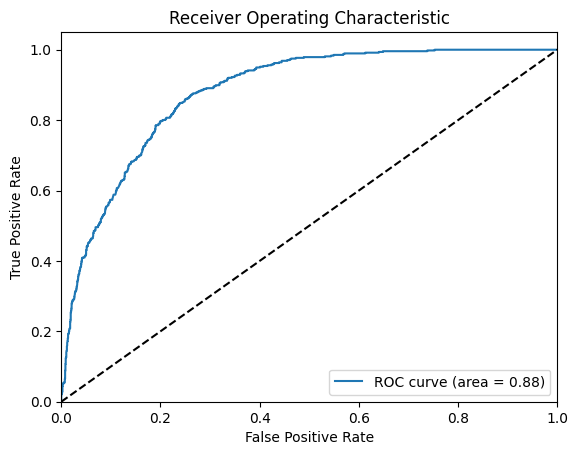

PR AUC: 0.6472567469608254


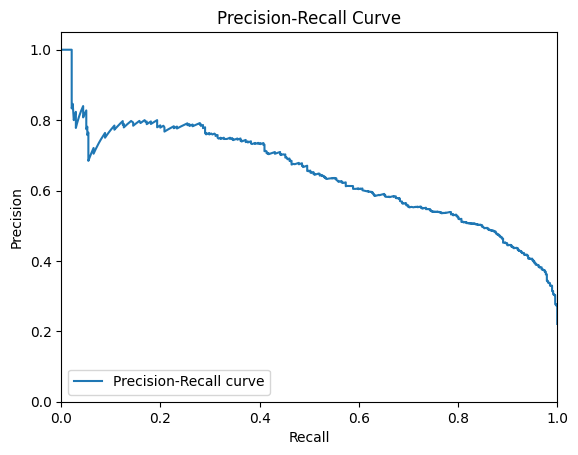

 69%|██████▉   | 9/13 [01:03<00:15,  3.95s/it]


Confusion Matrix:
 [[1444  235]
 [ 140  336]]


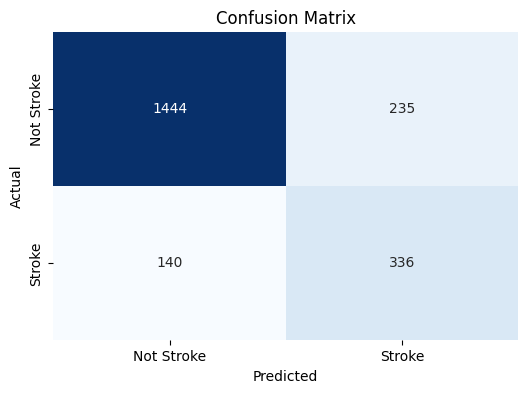


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.91      0.86      0.89      1679
      Stroke       0.59      0.71      0.64       476

    accuracy                           0.83      2155
   macro avg       0.75      0.78      0.76      2155
weighted avg       0.84      0.83      0.83      2155

ROC-AUC: 0.8793793574606734


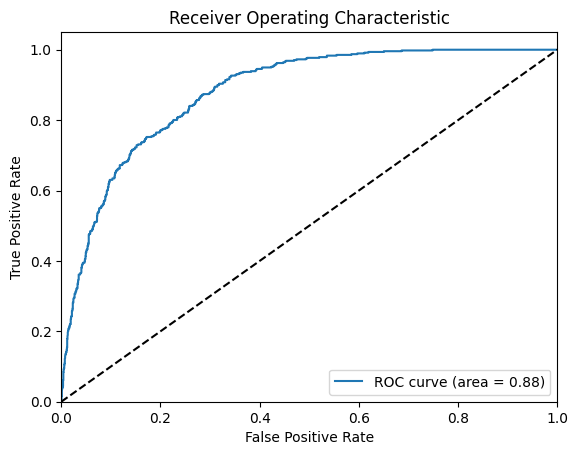

PR AUC: 0.6546628083538165


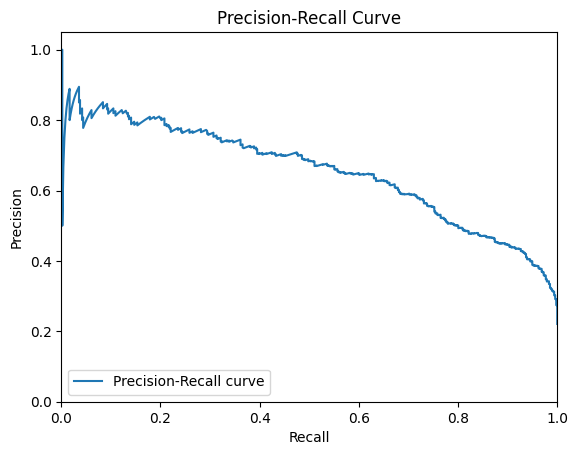

 77%|███████▋  | 10/13 [01:04<00:09,  3.09s/it]/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [15:38:01] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[1496  183]
 [ 201  275]]


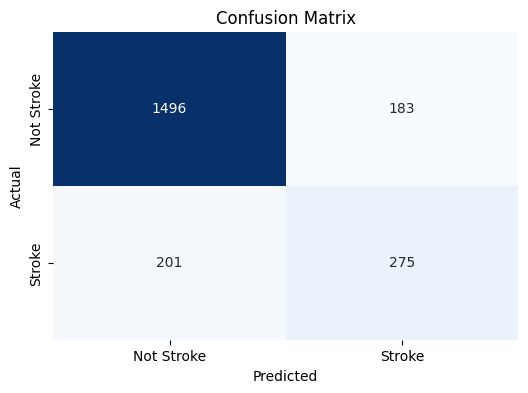


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.88      0.89      0.89      1679
      Stroke       0.60      0.58      0.59       476

    accuracy                           0.82      2155
   macro avg       0.74      0.73      0.74      2155
weighted avg       0.82      0.82      0.82      2155

ROC-AUC: 0.8680530878223834


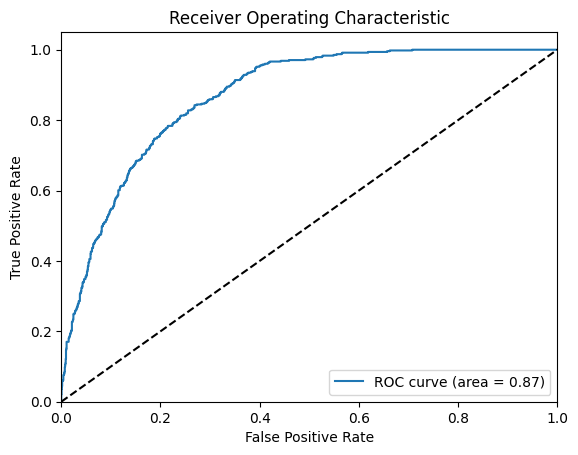

PR AUC: 0.6270549441068847


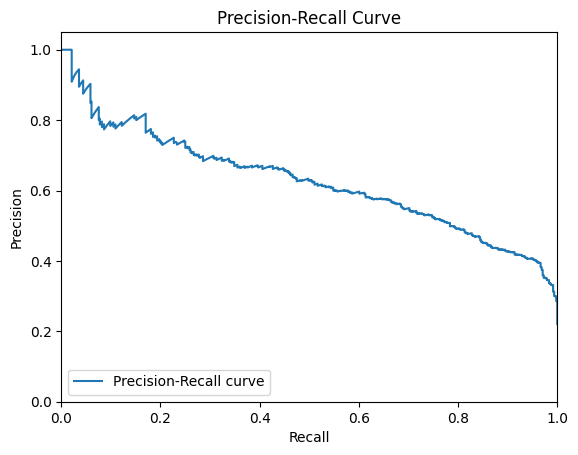

 85%|████████▍ | 11/13 [01:05<00:04,  2.40s/it]


Confusion Matrix:
 [[1503  176]
 [ 182  294]]


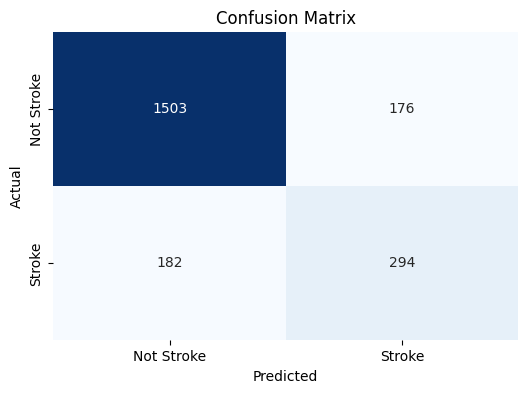


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.90      0.89      1679
      Stroke       0.63      0.62      0.62       476

    accuracy                           0.83      2155
   macro avg       0.76      0.76      0.76      2155
weighted avg       0.83      0.83      0.83      2155

ROC-AUC: 0.8830298647153918


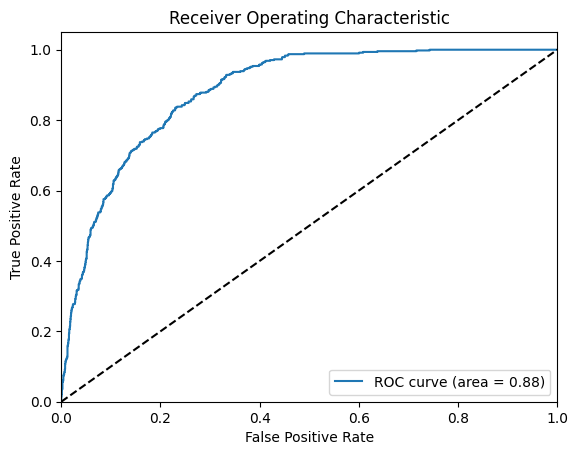

PR AUC: 0.6530567033329908


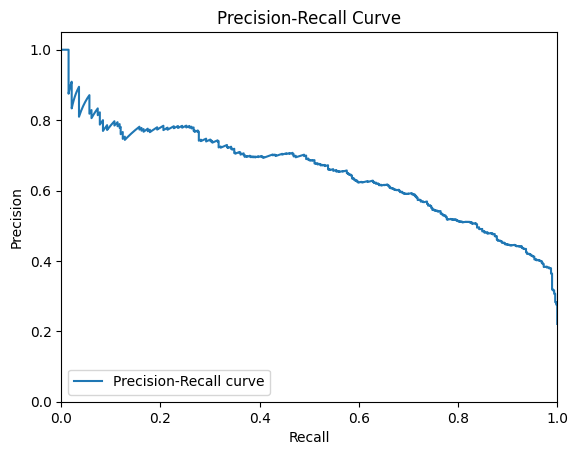

 92%|█████████▏| 12/13 [01:14<00:04,  4.33s/it]

[LightGBM] [Info] Number of positive: 6741, number of negative: 6741
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002502 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1918
[LightGBM] [Info] Number of data points in the train set: 13482, number of used features: 9
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000

Confusion Matrix:
 [[1481  198]
 [ 169  307]]


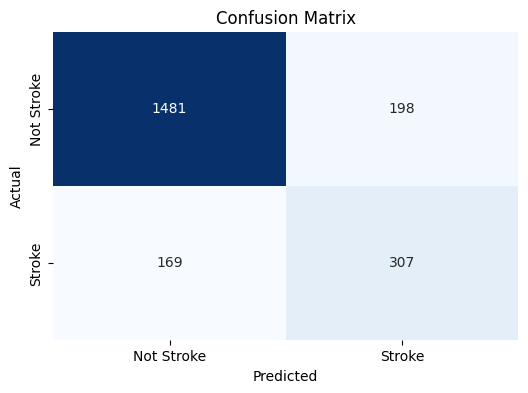


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.90      0.88      0.89      1679
      Stroke       0.61      0.64      0.63       476

    accuracy                           0.83      2155
   macro avg       0.75      0.76      0.76      2155
weighted avg       0.83      0.83      0.83      2155

ROC-AUC: 0.8798435693515048


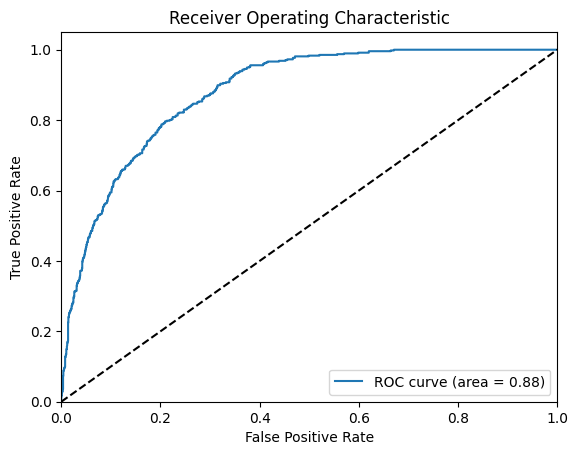

PR AUC: 0.6555661447647018


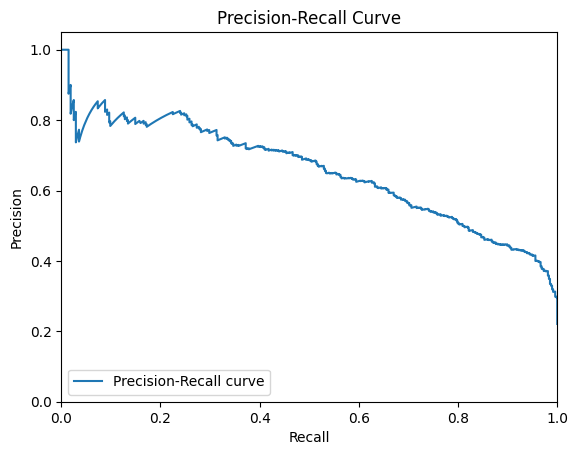

100%|██████████| 13/13 [01:14<00:00,  5.76s/it]


In [41]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [15:38:28] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[1396  283]
 [ 148  328]]


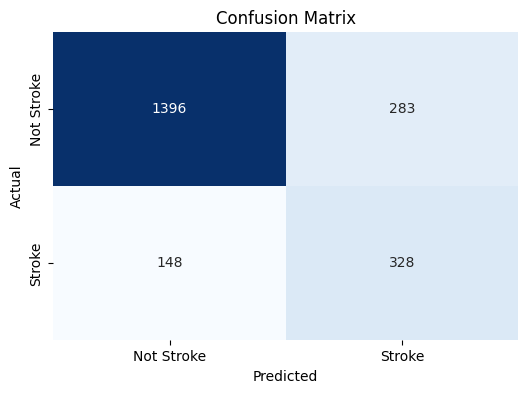


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.90      0.83      0.87      1679
      Stroke       0.54      0.69      0.60       476

    accuracy                           0.80      2155
   macro avg       0.72      0.76      0.73      2155
weighted avg       0.82      0.80      0.81      2155

ROC-AUC: 0.8692686723289673


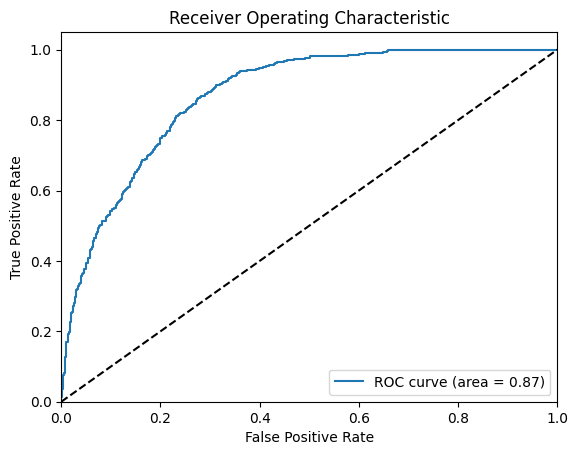

PR AUC: 0.631523414979035


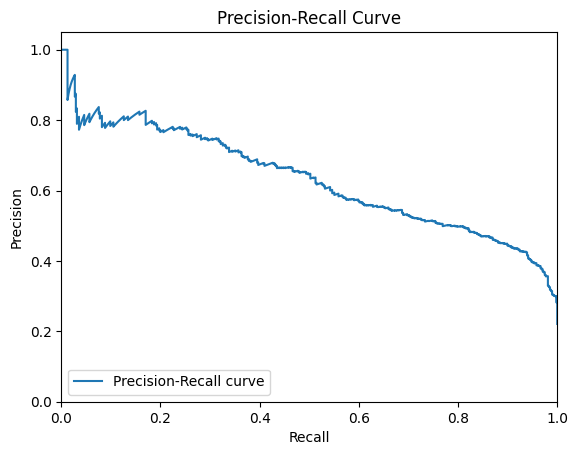

In [42]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(X_train, y_train)
voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = voting_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred),
    "Test Precision": precision_score(y_test, voting_test_pred),
    "Train Recall": recall_score(y_train, voting_train_pred),
    "Test Recall": recall_score(y_test, voting_test_pred),
    "Train F1 Score": f1_score(y_train, voting_train_pred),
    "Test F1 Score": f1_score(y_test, voting_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [15:39:19] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "max_iter" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[1518  161]
 [ 226  250]]


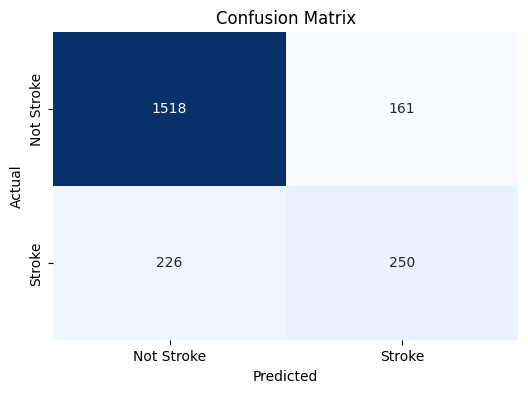


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.90      0.89      1679
      Stroke       0.61      0.53      0.56       476

    accuracy                           0.82      2155
   macro avg       0.74      0.71      0.73      2155
weighted avg       0.81      0.82      0.82      2155

ROC-AUC: 0.8558540748044304


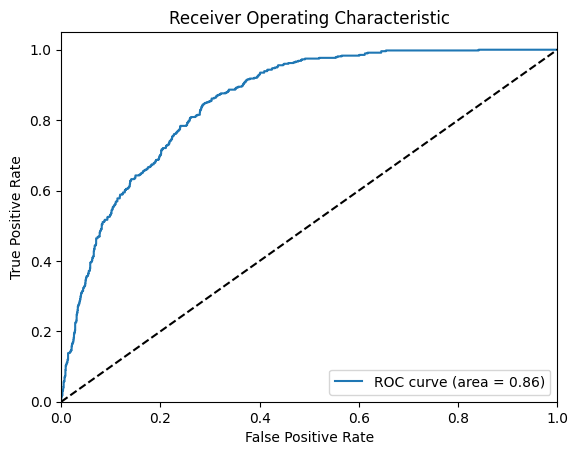

PR AUC: 0.5909491652432359


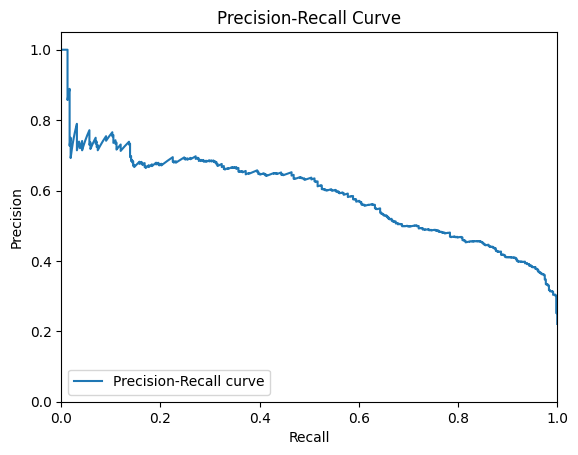

In [43]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),


    ],
    final_estimator=XGBClassifier(max_iter=2000),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(X_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train)
stack_auto_test_pred  = stack_auto.predict(X_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [44]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)

In [45]:
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Hist Gradient Boosting,0.899051,0.825986,0.881128,0.588441,0.922563,0.705882,0.901370,0.641834,0.899051,0.782959,0.879379,0.654663
Gradient Boosting,0.847797,0.800928,0.812475,0.533333,0.904317,0.789916,0.855939,0.636749,0.847797,0.796983,0.878728,0.647257
AdaBoost,0.802403,0.780974,0.776257,0.502545,0.849726,0.829832,0.811331,0.625990,0.802403,0.798478,0.870511,0.629613
LightGBM,0.909286,0.829698,0.899508,0.607921,0.921525,0.644958,0.910383,0.625892,0.909286,0.763515,0.879844,0.655566
CatBoost,0.916333,0.833875,0.914121,0.625532,0.919003,0.617647,0.916556,0.621564,0.916333,0.756411,0.883030,0.653057
SVC,0.824655,0.751740,0.772439,0.466817,0.920487,0.871849,0.839989,0.608059,0.824655,0.794769,0.861883,0.581161
Voting Classifier,0.927310,0.800000,0.903601,0.536825,0.956683,0.689076,0.929385,0.603496,0.927310,0.760261,0.869269,0.631523
XGBoost,0.941107,0.821810,0.943607,0.600437,0.938288,0.577731,0.940940,0.588865,0.941107,0.734369,0.868053,0.627055
Random Forest,1.000000,0.811601,1.000000,0.569444,1.000000,0.602941,1.000000,0.585714,1.000000,0.736849,0.855245,0.586111
Naive Bayes,0.754487,0.733179,0.731106,0.441558,0.805073,0.785714,0.766309,0.565382,0.754487,0.751999,0.835367,0.587567


<Axes: >

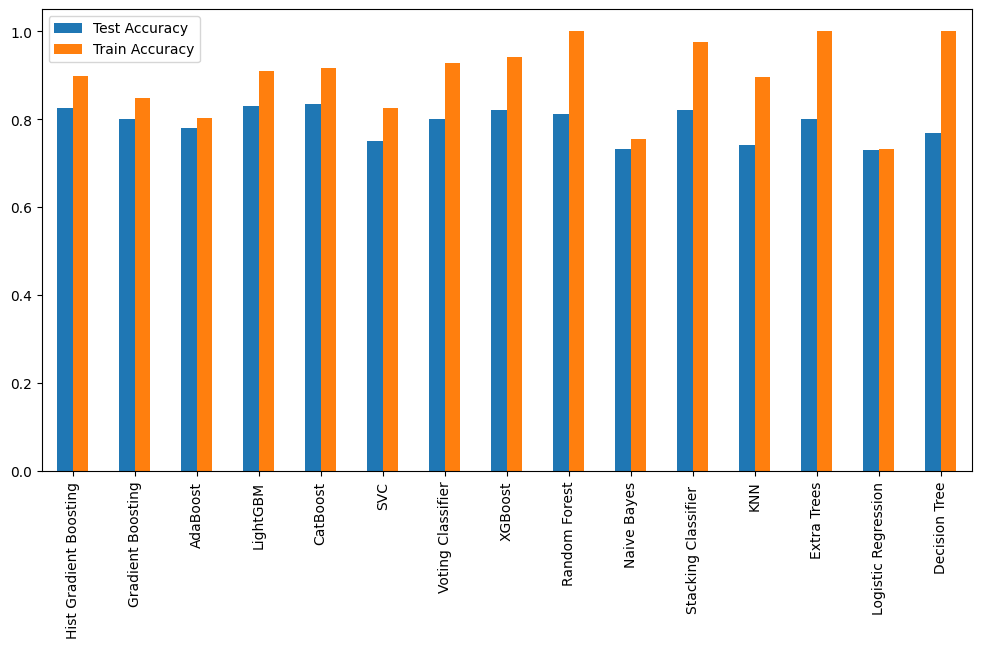

In [46]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

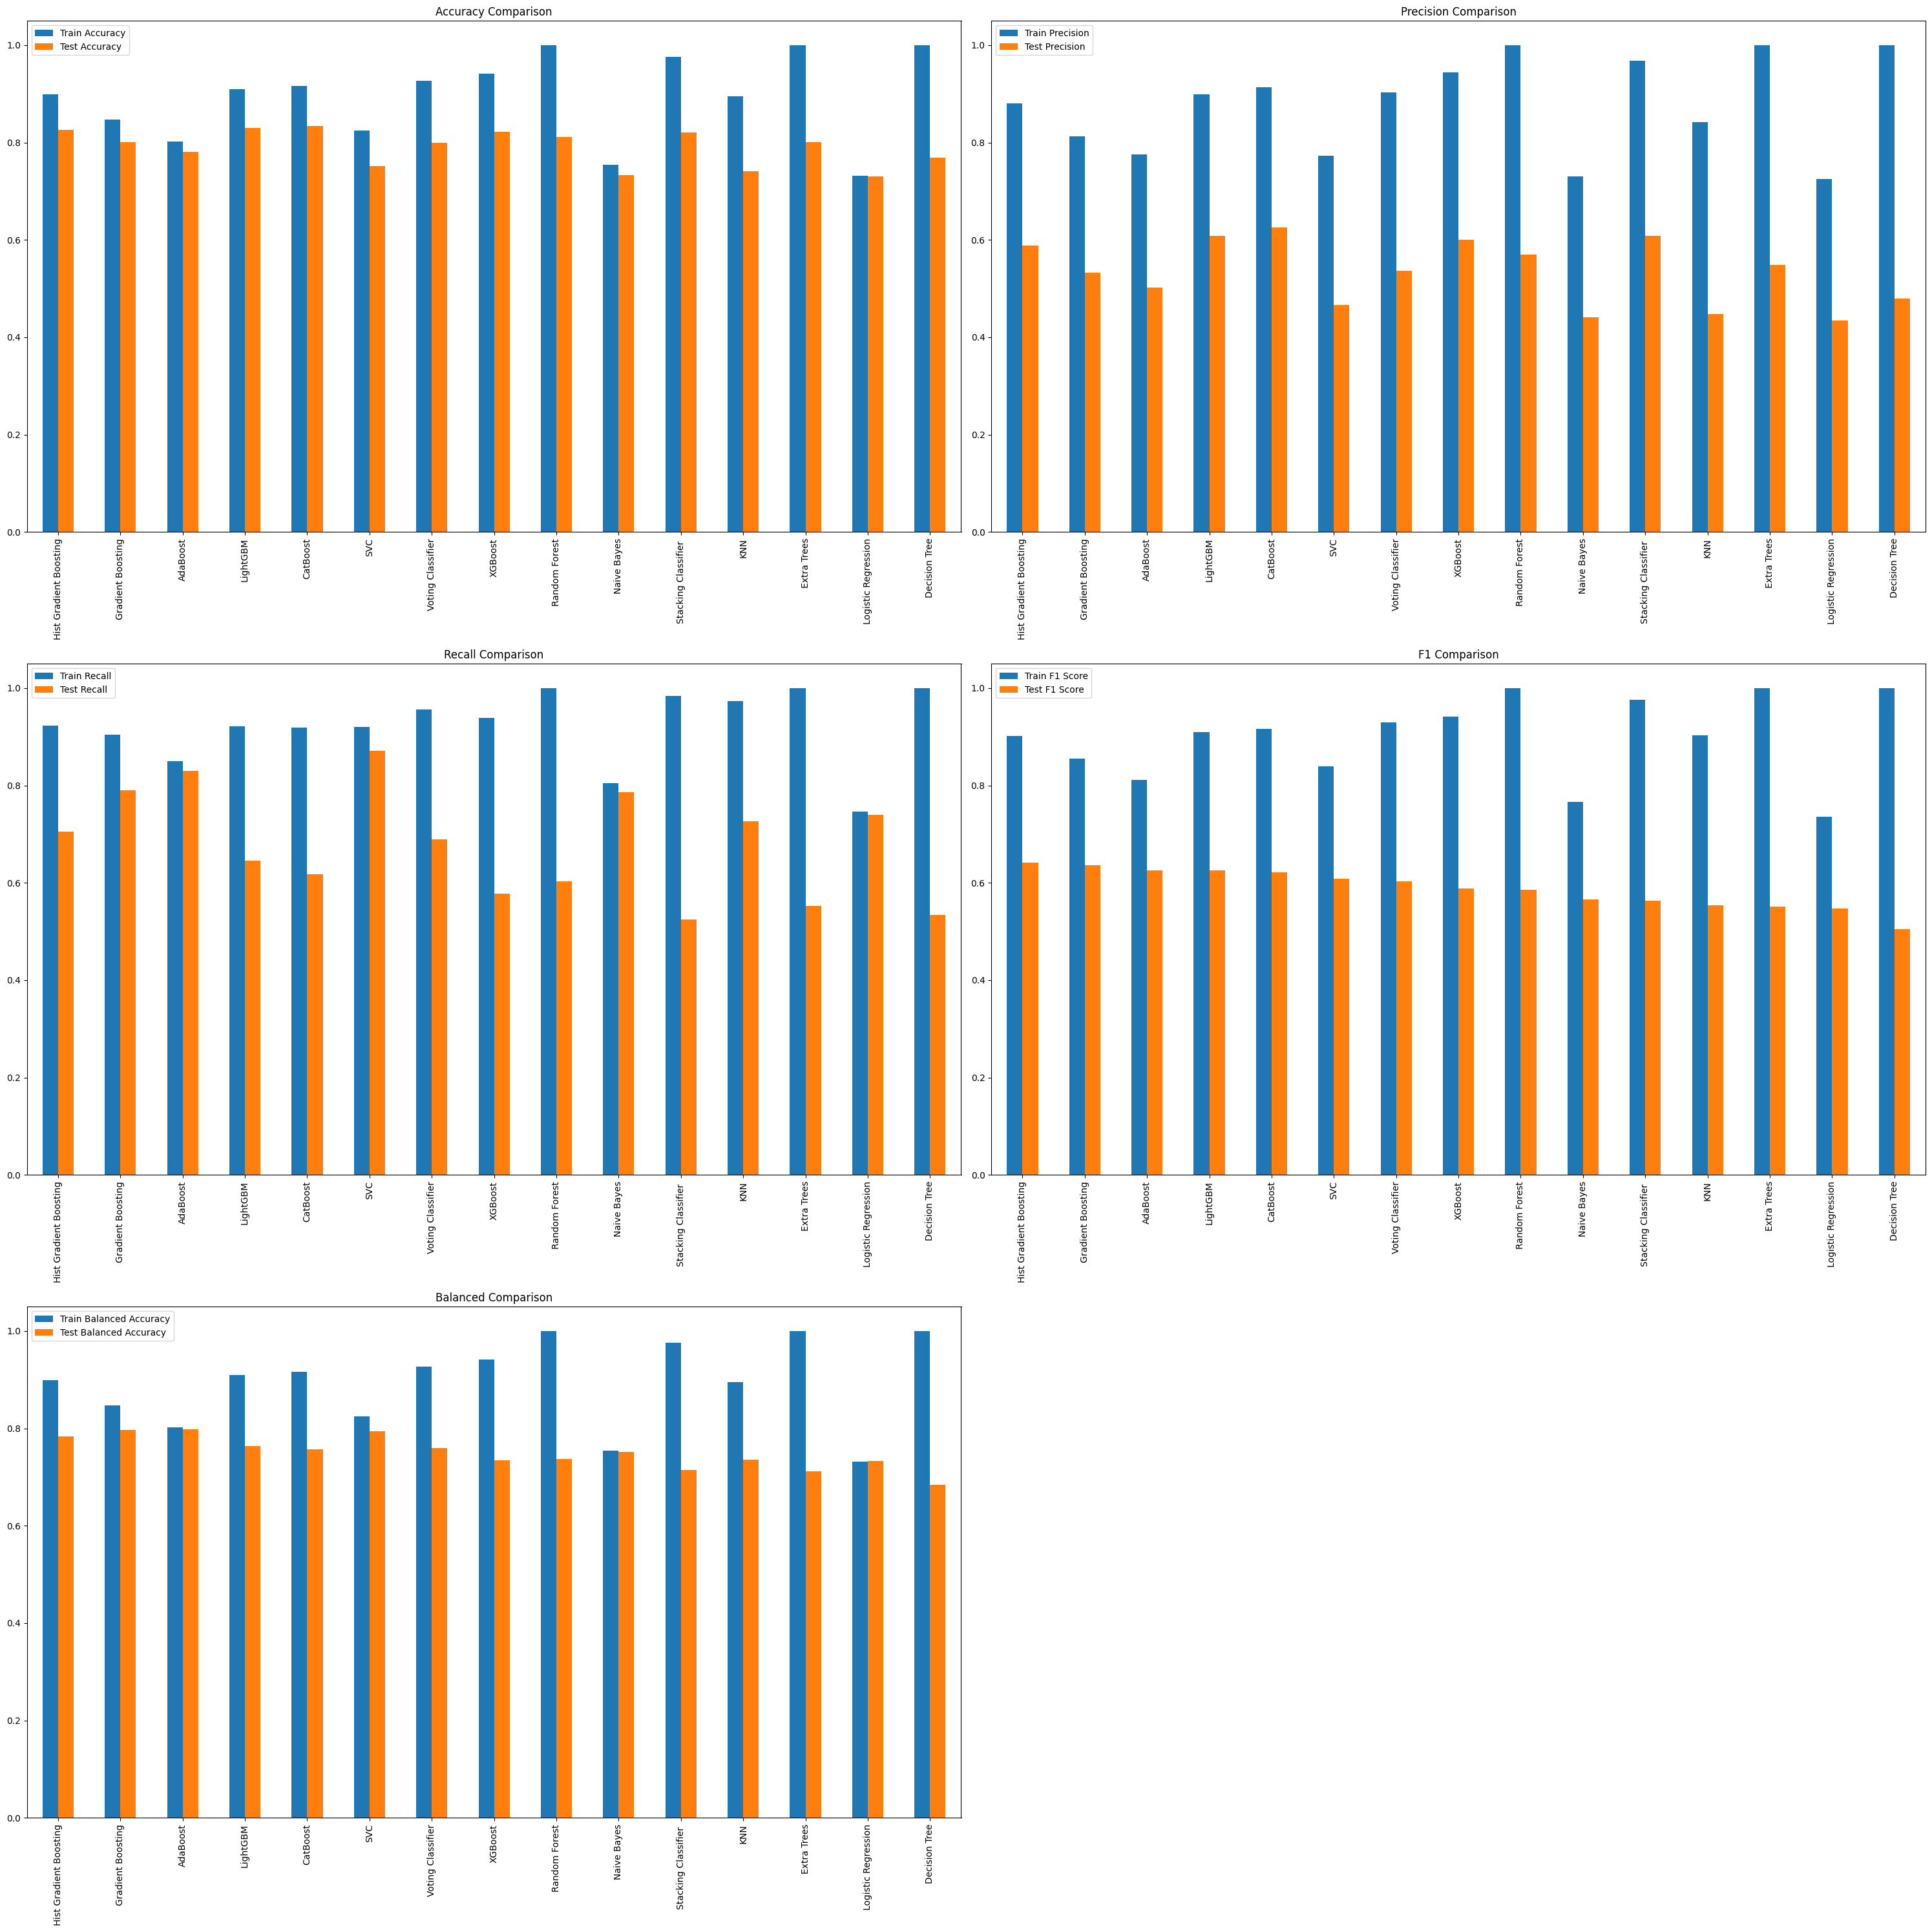

In [47]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()